## Course Announcements

Due Sunday:
- A5
- Q6
- Project: Checkpoint #1: Data
- [weekly project survey](https://forms.gle/pRqEYm8rZQH4Ezcp7) (for EC) - complete weekly

Notes:
- Project Proposal Feedback to be posted today
- Thanks for mid-course feedback!
    - Discussion: want more project-centered time; readings not engaging
    - Room capacity notes
    - Group project concerns
    - Pace: too fast, too slow
    - Discussion forms: prefer 1/lecture
    - Assignments - learn on own


# Dimensionality Reduction

Today's question: **when a dataset has too many variables to look at, how do we summarize them with just a few?**

- What dimensionality reduction is, and the two ways we use it
    - EDA for wide datasets
    - fewer features going into a model
- **Principal Component Analysis (PCA)**
    - principal components, **loadings**, and **scores**
    - **scale** your features first (when they're in different units)
    - choosing **how many components** to keep: scree plot, % variance explained, interpretability
- Case studies: diet in the UK, and genes mirroring geography in Europe
- Beyond PCA: nonlinear methods (**t-SNE**) and how (not) to read them

(This is the material for **A5 Part 4**. You'll use PCA again before a model in **A6**.)

## Contents

Reminder; In JupyterLab, the table of contents sidebar, the bulleted-list icon on the left, shows the same outline and highlights the section you're in.

- [1. Setup](#s1)
- [2. What Is Dimensionality Reduction?](#s2) · [2a. Why Reduce Dimensions?](#s2a)
- [3. PCA in Two Dimensions](#s3) · [3a. The Data](#s3a) · [3b. Finding the Principal Components](#s3b) · [3c. Loadings and Scores](#s3c) · [3d. Keeping Only PC1](#s3d)
- [4. Case Study: Diet in the UK](#s4) · [4a. Look at the Raw Data](#s4a) · [4b. Run the PCA](#s4b) · [4c. What Drives PC1?](#s4c) · [4d. How Many PCs?](#s4d)
- [5. Case Study: Genes Mirror Geography](#s5)
- [6. More Features: Wine](#s6) · [6a. Scale First](#s6a) · [6b. How Many Components to Keep?](#s6b) · [6c. Plot the Scores](#s6c)
- [7. Beyond PCA: t-SNE](#s7) · [7a. PCA vs. t-SNE](#s7a) · [7b. Reading a t-SNE Plot](#s7b)
- [8. Summary: Pros, Cons & a Checklist](#s8)
- [9. On Your Own](#s9) · [9a. What's Lost When Keeping Only PC1](#s9a) · [9b. Interpreting the Wine Loadings](#s9b) · [9c. PCA Before a Model](#s9c) · [9d. The Swiss Roll](#s9d) · [9e. PCA by Hand](#s9e) · [9f. Compressing Images with PCA](#s9f) · [9g. t-SNE's Perplexity](#s9g) · [9h. UMAP](#s9h)

## 1. Setup <a id="s1"></a>

In [1]:
import pandas as pd
import numpy as np

# Import seaborn and apply its plotting styles
import seaborn as sns
sns.set_theme(style="white",
              font_scale=2,
              rc={'axes.spines.right': False,'axes.spines.top': False}) # this last thing is equivalent to always having sns.despine()

# import matplotlib
import matplotlib.pyplot as plt
# set plotting size parameter
plt.rcParams['figure.figsize'] = (8, 8)

# scikit-learn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 2. What Is Dimensionality Reduction? <a id="s2"></a>

Each column (variable, feature) in a dataset is a **dimension**. So far, EDA has meant looking at variables one or two at a time:

| Approach | What it helps you understand | Examples |
|---|---|---|
| Univariate | a single variable | histogram, density plot, bar plot |
| Bivariate | the relationship between 2 variables | scatterplot, boxplot, grouped bar plot |
| **Dimensionality reduction** | many variables at once, by projecting high-dimensional data into a lower-dimensional space | PCA, t-SNE, UMAP (and, related, clustering) |

**Dimensionality reduction** is a mathematical process to reduce the number of variables you have to consider, while keeping as much of the information in them as possible.

Why not just look at every pair of variables? With $p$ variables there are $p(p-1)/2$ scatterplots:

In [2]:
for p in [2, 17, 13, 64, 197_146]:
    print(f'{p:>9,} variables -> {p * (p - 1) // 2:>17,} scatterplots')

        2 variables ->                 1 scatterplots
       17 variables ->               136 scatterplots
       13 variables ->                78 scatterplots
       64 variables ->             2,016 scatterplots
  197,146 variables ->    19,433,174,085 scatterplots


Those are the datasets you'll see today: 2 exam scores, 17 foods, 13 chemical measurements of wine, 64 pixels, and 197,146 genetic variants. Past a handful of variables, looking at them in pairs stops working.

### 2a. Why Reduce Dimensions? <a id="s2a"></a>

There are two main ways to use dimensionality reduction:

1. **Like EDA, for wide datasets**: gain insight, see which observations are similar, and see how the variables relate to one another.
2. **As a feature transformation before a model**: a smaller number of variables means less data needed, faster and easier learning, and less redundancy among predictors.

Some use cases:

| Data | Goal |
|---|---|
| Thousands of sensors monitoring an industrial process | reduce them to a few features, then build an interpretable model that predicts process failure |
| How much of each food people eat, across populations | identify which populations have similar diets |
| Genetic variation at hundreds of thousands of positions in the genome | learn about genetic ancestry and history |

## 3. PCA in Two Dimensions <a id="s3"></a>

**Principal Component Analysis (PCA)** combines many numeric variables into a smaller set of new variables, called **principal components (PCs)**.

- Each PC is a **weighted linear combination** of the original variables.
- PC1 is the combination that captures as much of the total variance as possible. PC2 captures as much of the *remaining* variance as possible, and is uncorrelated with PC1. And so on, until there are as many PCs as original variables.
- A handful of PCs usually captures most of the variance, so you can keep those and drop the rest.

Key terms:

| Term | What it is |
|---|---|
| **Principal component (PC)** | a new variable: a weighted combination of the original variables |
| **Loadings** (weights) | the weights that turn the original variables into a PC. They tell you which original variables contribute to that PC, and in which direction. |
| **Scores** | each observation's value on each PC (its coordinates in the new space) |
| **Scree plot** | a plot of the variance explained by each PC |

PCA really shines with many variables, but it's easiest to *see* with two.

### 3a. The Data <a id="s3a"></a>

*Simulated* midterm and final exam scores for 200 students. Students who did well on the midterm tend to do well on the final, so the two are correlated.

In [3]:
rng = np.random.default_rng(108)
n_students = 200

# each student has an underlying 'ability'; each exam measures it with some noise
ability = rng.normal(72, 8, n_students)
exams = pd.DataFrame({'midterm': ability + rng.normal(0, 4, n_students),
                      'final': ability + rng.normal(0, 4, n_students)}).clip(upper=100).round(1)
exams.head()

,midterm,final
0,100.0,93.5
1,76.5,78.6
2,95.4,91.8
3,60.7,63.0
4,84.5,83.8


correlation: 0.84


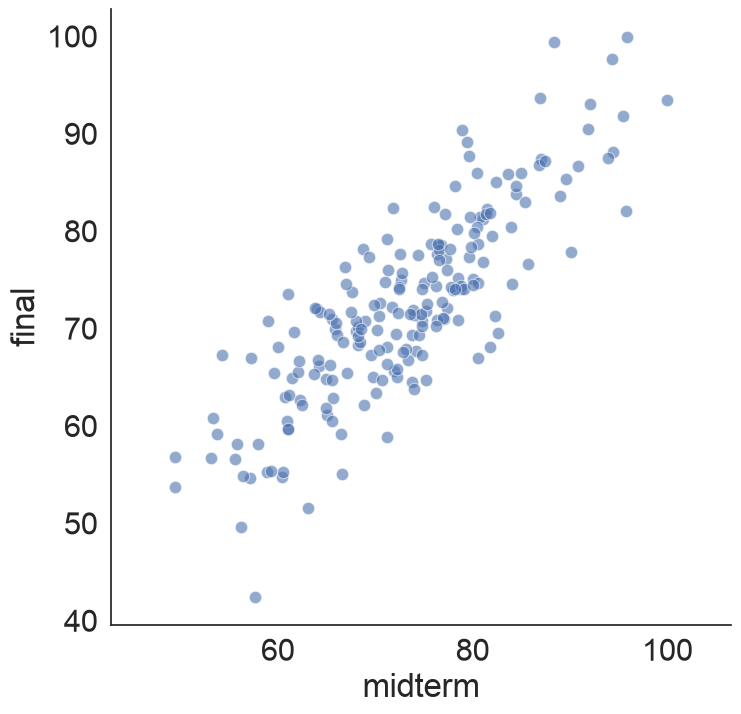

In [4]:
sns.scatterplot(x='midterm', y='final', data=exams, s=80, alpha=0.6)
plt.axis('equal');

print('correlation:', round(exams['midterm'].corr(exams['final']), 2))

Suppose we had to describe each student with **one** number instead of two. We could keep only the midterm, but then we'd throw away everything the final tells us.

PCA instead looks for a **new axis** that runs along the direction where the data are most spread out.

### 3b. Finding the Principal Components <a id="s3b"></a>

`scikit-learn`'s `PCA` works like the other `sklearn` tools you'll see in this class: create the object, then `.fit()` it to the data.

In [5]:
pca_exams = PCA()
pca_exams.fit(exams)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

`PCA` **centers** each variable for you (subtracts its mean) but it does **not** scale it. Both exams are on the same 0-100 scale, so that's fine here. (Section 6 shows what happens when variables are in different units.)

Let's draw the two PCs on top of the data. Each arrow points along one PC, and its length shows how spread out the data are in that direction (2 standard deviations).

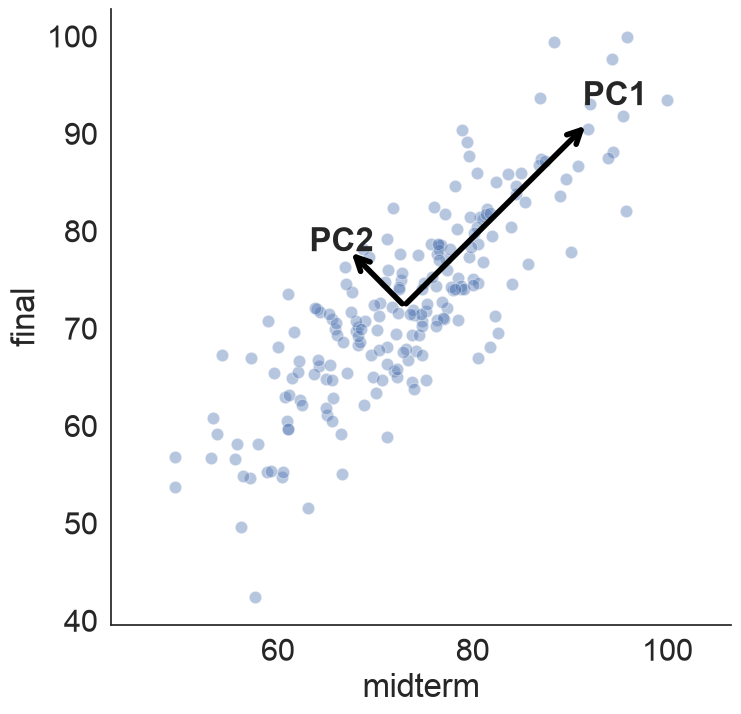

In [6]:
center = exams.mean().values

sns.scatterplot(x='midterm', y='final', data=exams, s=80, alpha=0.4)
for name, direction, variance in zip(['PC1', 'PC2'], pca_exams.components_, pca_exams.explained_variance_):
    arrow = direction * 2 * np.sqrt(variance)
    plt.annotate('', xy=center + arrow, xytext=center,
                 arrowprops=dict(arrowstyle='->', lw=4, color='black'))
    plt.text(*(center + arrow * 1.15), name, fontweight='bold', ha='center', va='center')
plt.axis('equal');

- **PC1** runs along the cloud of points: the direction of the most variance.
- **PC2** is perpendicular to PC1 and captures what's left.

How much of the total variance does each PC capture?

In [7]:
pca_exams.explained_variance_ratio_.round(3)

array([0.918, 0.082])

PC1 alone captures >90% of the variance in the two exam scores.

### 3c. Loadings and Scores <a id="s3c"></a>

The **loadings** are stored in `.components_` (one row per PC, one column per original variable). Transposing makes them easier to read:

In [8]:
loadings_exams = pd.DataFrame(pca_exams.components_.T,
                              index=exams.columns,
                              columns=['PC1', 'PC2'])
loadings_exams.round(2)

,PC1,PC2
midterm,0.71,-0.70
final,0.70,0.71


For two input variables ($X_1$ = midterm, $X_2$ = final, both centered), the two PCs are

$$Z_1 = w_{1,1}X_1 + w_{1,2}X_2$$
$$Z_2 = w_{2,1}X_1 + w_{2,2}X_2$$

where the $w$'s are the loadings. Read them like this:

- **PC1**: both exams get about the same weight (about 0.7), with the **same** sign. PC1 is roughly the student's **overall performance**.
- **PC2**: about the same size weights, with **opposite** signs. PC2 is roughly **final - midterm**: who improved, and who slipped.

⚠️ **The sign of a PC is arbitrary.** Flipping every loading of a PC (and every score on it) describes exactly the same axis, and you may get the opposite signs on a different computer or `sklearn` version. Interpret which variables have big loadings, and whether they share a sign, not whether a PC is "positive."

The **scores** are each student's coordinates on the new axes. `.transform()` computes them:

In [9]:
exam_scores = pca_exams.transform(exams)
exam_scores_df = pd.DataFrame(exam_scores, columns=['PC1', 'PC2'])
exam_scores_df.head()

,PC1,PC2
0,34.092946,-4.037135
1,6.919001,1.949242
2,29.631048,-2.002075
3,-15.284510,2.013222
4,16.259659,0.001910


Check the interpretation: PC1 should rank students almost exactly like their average exam score does, and PC2 like their improvement.

In [10]:
print('PC1 vs. average of the two exams:', round(np.corrcoef(exam_scores[:, 0], exams.mean(axis=1))[0, 1], 3))
print('PC2 vs. final - midterm:          ', round(np.corrcoef(exam_scores[:, 1], exams['final'] - exams['midterm'])[0, 1], 3))

PC1 vs. average of the two exams: 1.0
PC2 vs. final - midterm:           1.0


(Each correlation is close to +1 or -1. The sign just depends on which way the PC happened to point.)

### 3d. Keeping Only PC1 <a id="s3d"></a>

**Dimensionality reduction** is keeping only the first few PCs. Here, we keep 1 of 2 with `n_components=1`. `.fit_transform()` fits and transforms in one step.

In [11]:
pca_1d = PCA(n_components=1)
exams_1d = pca_1d.fit_transform(exams)

print('original shape:', exams.shape)
print('reduced shape: ', exams_1d.shape)
print('variance kept: ', round(pca_1d.explained_variance_ratio_.sum(), 3))

original shape: (200, 2)
reduced shape:  (200, 1)
variance kept:  0.918


We kept 92% of the variance with half as many variables. (What exactly did we throw away? See [9a](#s9a) in On Your Own.)

## 4. Case Study: Diet in the UK <a id="s4"></a>

How much of 17 types of food did people eat (grams per person per week, 1997) in each of the four countries of the UK? (Data from DEFRA, the UK's Department for Environment, Food & Rural Affairs; it's the example in the [setosa.io PCA explainer](https://setosa.io/ev/principal-component-analysis/).)

### 4a. Look at the Raw Data <a id="s4a"></a>

In [12]:
diet = pd.read_csv('data/uk_foods.csv', index_col='food')
diet

,England,Wales,Scotland,N.Ireland
food,,,,
Cheese,105,103,103,66
Carcass meat,245,227,242,267
Other meat,685,803,750,586
Fish,147,160,122,93
Fats and oils,193,235,184,209
Sugars,156,175,147,139
Fresh potatoes,720,874,566,1033
Fresh Veg,253,265,171,143
Other Veg,488,570,418,355


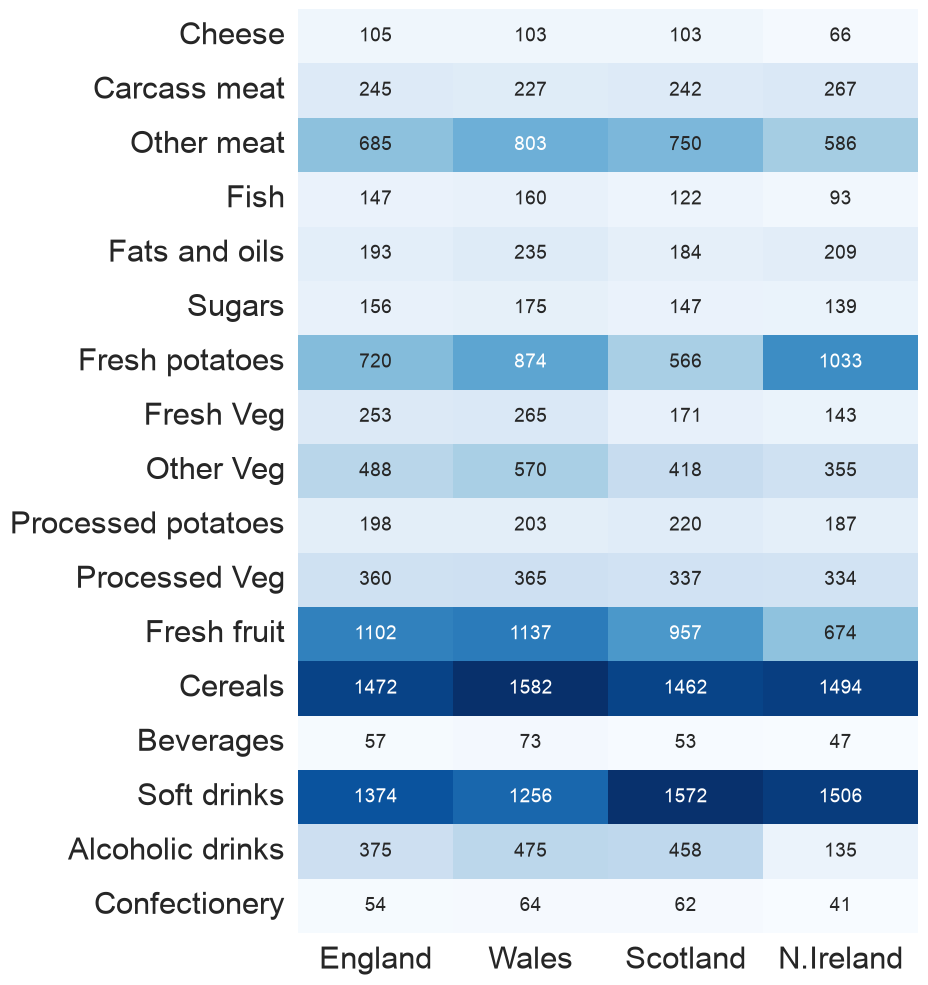

In [13]:
plt.figure(figsize=(8, 12))
sns.heatmap(diet, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={'size': 14})
plt.ylabel('');

17 foods x 4 countries is a small table... and it's still hard to say which country's diet is the most different from the others, or in what way.

### 4b. Run the PCA <a id="s4b"></a>

PCA treats **rows as observations** and **columns as variables**. We want to compare *countries* using their *foods*, so countries need to be the rows: transpose with `.T`.

Should we scale? Every food is measured in the same units (grams per person per week), so we'll just center the data, the same as the setosa.io example. That means foods eaten in large amounts (potatoes, fruit, soft drinks) can count for more. (Try adding `StandardScaler()` on your own. In this dataset the overall picture is the same.)

In [14]:
X_diet = diet.T     # rows = countries (observations), columns = foods (variables)
print(X_diet.shape)

pca_diet = PCA()
diet_scores = pca_diet.fit_transform(X_diet)

diet_scores_df = pd.DataFrame(diet_scores[:, :2], index=X_diet.index, columns=['PC1', 'PC2'])
diet_scores_df.round(1)

(4, 17)


,PC1,PC2
England,145.0,2.5
Wales,240.5,224.6
Scotland,91.9,-286.1
N.Ireland,-477.4,58.9


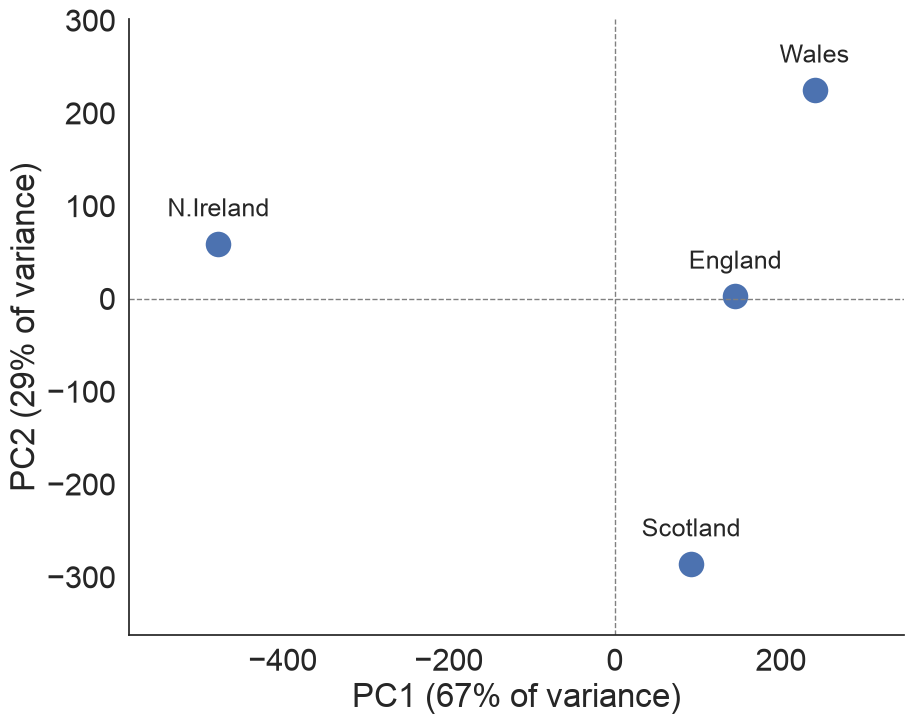

In [15]:
pct = pca_diet.explained_variance_ratio_ * 100

plt.figure(figsize=(10, 8))
sns.scatterplot(x='PC1', y='PC2', data=diet_scores_df, s=400)
for country, row in diet_scores_df.iterrows():
    plt.text(row['PC1'], row['PC2'] + 30, country, ha='center', fontsize=18)
plt.axhline(0, color='gray', lw=1, ls='--')
plt.axvline(0, color='gray', lw=1, ls='--')
plt.margins(0.15)
plt.xlabel(f'PC1 ({pct[0]:.0f}% of variance)')
plt.ylabel(f'PC2 ({pct[1]:.0f}% of variance)');

Now it jumps out: along PC1 (two-thirds of the variance), **Northern Ireland sits far from the other three countries**.

### 4c. What Drives PC1? <a id="s4c"></a>

#### Question #1

<img src="QRCodes/11_01.png" width="140" align="right">

Which foods do you think separate Northern Ireland from England, Scotland, and Wales along PC1?

- A) Cereals and cheese
- B) Fresh potatoes, fresh fruit, and alcoholic drinks
- C) Soft drinks and confectionery (sweets)
- D) Fish and sugars

Poll: https://forms.gle/JzraZxnR5ZGdHASS9

The loadings tell us. A food with a large loading (positive *or* negative) contributes a lot to PC1. A food with a loading near 0 barely matters.

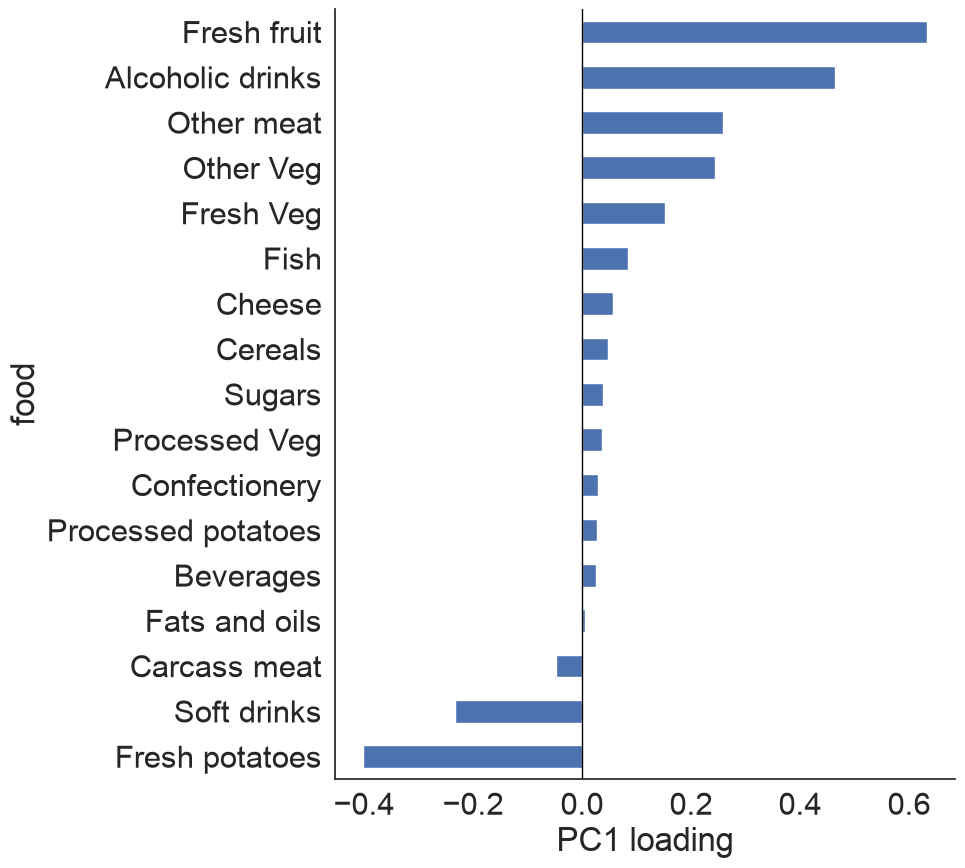

In [16]:
diet_loadings = pd.DataFrame(pca_diet.components_[:2].T,
                             index=X_diet.columns,
                             columns=['PC1', 'PC2'])

diet_loadings['PC1'].sort_values().plot.barh(figsize=(8, 10))
plt.axvline(0, color='black', lw=1)
plt.xlabel('PC1 loading');

How to read this: foods whose loadings have the **same sign as a country's PC1 score** are eaten **more** in that country than average, and foods with the **opposite sign** are eaten less. (If PC1's sign flips on your computer, everything flips together, so the conclusion doesn't change.)

Check it against the raw data:

In [17]:
diet.loc[['Fresh potatoes', 'Fresh fruit', 'Alcoholic drinks', 'Fresh Veg', 'Other meat']]

,England,Wales,Scotland,N.Ireland
food,,,,
Fresh potatoes,720,874,566,1033
Fresh fruit,1102,1137,957,674
Alcoholic drinks,375,475,458,135
Fresh Veg,253,265,171,143
Other meat,685,803,750,586


Northern Ireland eats far more fresh potatoes, and far less fresh fruit, alcohol, fresh vegetables, and "other" meat. We found that from one plot and one set of loadings, instead of staring at a 17 x 4 table.

### 4d. How Many PCs? <a id="s4d"></a>

We have 4 countries (observations) and 17 foods (variables). How many principal components capture **any** (non-zero) variance?

[0.674 0.291 0.035 0.   ]


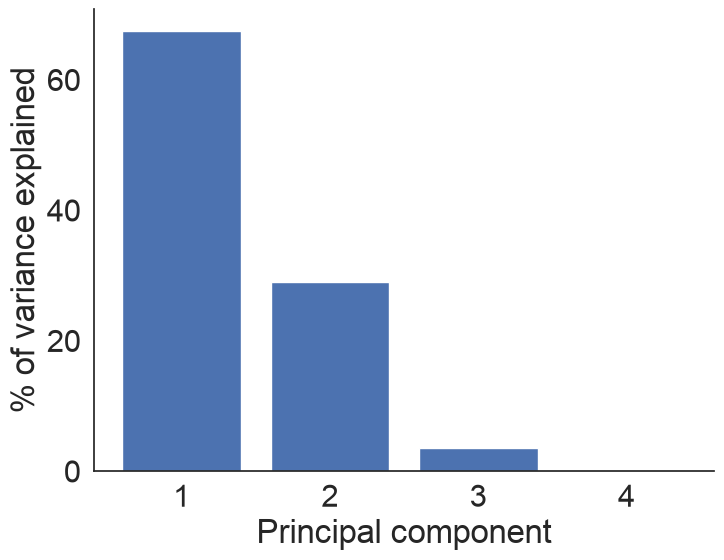

In [18]:
plt.figure(figsize=(8, 6))
plt.bar(range(1, len(pct) + 1), pct)
plt.xticks(range(1, len(pct) + 1))
plt.xlabel('Principal component')
plt.ylabel('% of variance explained');

print(pca_diet.explained_variance_ratio_.round(3))

`PCA()` returned 4 components (by default, the smaller of the number of rows and columns), and the 4th explains **0%**.

Why? Once the data are centered, any 4 points fit exactly into 3 dimensions (just as any 2 points lie on a line, and any 3 on a plane). In general:

$$\text{number of PCs with non-zero variance} \leq \min(n - 1,\ p)$$

where $n$ is the number of observations and $p$ the number of variables. With wide data ($p > n$), it's the number of observations that limits you.

## 5. Case Study: Genes Mirror Geography <a id="s5"></a>

Novembre et al. (2008), [*Genes mirror geography within Europe*](https://www.nature.com/articles/nature07331), *Nature*.

**SNPs** (single nucleotide polymorphisms):
- Your DNA is made up of four bases: G, C, T & A.
- A SNP is a position in the DNA where the base varies between people (by convention, the less common version appears in at least 1% of the population).
- Most are just normal human variation; some contribute to disease.
- Companies like 23andMe and Ancestry.com measure SNPs.

**The study:**
1. Measure the genotype of 1,387 Europeans with known ancestry at about 500,000 SNPs. (After filtering, the PCA used **197,146 SNPs**.)
2. Run PCA on that individuals x SNPs table.
3. Plot each person's PC1 vs. PC2 score, colored by where their grandparents came from.
4. Compare to a map of Europe.

**The result:** the PC1 vs. PC2 plot looks remarkably like a map of Europe. (Open the paper's Figure 1 to see it.) PC1 lines up with north-south and PC2 with east-west (after a slight rotation), even within countries: for example, the French-, German- and Italian-speaking Swiss each sit closest to France, Germany and Italy.

Two things to notice:
- **No geographic information went into the PCA.** Only DNA did. The structure came from the data.
- PC1 and PC2 explain only about **0.30%** and **0.15%** of the genetic variation. A tiny share of the variance can still be the most interesting structure in the data. Low % variance explained does not mean "unimportant."

#### Question #2

<img src="QRCodes/11_01.png" width="140" align="right">

The PCA used 197,146 SNPs (variables) from 1,387 people (observations). At most, how many principal components could capture non-zero variance?

- A) 2
- B) 1,386
- C) 197,146
- D) 198,533

Poll: https://forms.gle/JzraZxnR5ZGdHASS9

## 6. More Features: Wine <a id="s6"></a>

13 chemical measurements of 178 Italian wines, from three different cultivars (grape varieties). This dataset comes with `scikit-learn`, so there's nothing to download.

We'll run PCA on the 13 measurements **only**, and use the cultivar afterwards to see whether PCA found structure on its own.

In [ ]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
X_wine = wine.data                          # the 13 measurements
cultivar = wine.target.map({0: 'A', 1: 'B', 2: 'C'})

X_wine.head()

### 6a. Scale First <a id="s6a"></a>

In [ ]:
X_wine.describe().T[['mean', 'std', 'min', 'max']].round(2)

#### Question #3

<img src="QRCodes/11_01.png" width="140" align="right">

If we run PCA on the wine data **without scaling it first**, which feature will dominate PC1?

- A) `alcohol`
- B) `hue`
- C) `proline`
- D) All 13 contribute about equally

Poll: https://forms.gle/JzraZxnR5ZGdHASS9

In [ ]:
pca_unscaled = PCA().fit(X_wine)

print('variance explained by PC1:', round(pca_unscaled.explained_variance_ratio_[0], 3))
pd.Series(pca_unscaled.components_[0], index=X_wine.columns).round(3).sort_values()

Without scaling, PC1 "explains" 99.8% of the variance, and it's just `proline`. That's not because proline is the most important measurement. It's because proline's numbers are in the hundreds to thousands, while most others are under 10. **PCA finds directions of maximum variance, so variables with big numbers win.**

The fix is to **standardize** (z-score) each variable so it has mean 0 and standard deviation 1. This is exactly A5 4a.

Rule of thumb:
- variables in **different units** (or very different ranges): **scale** them
- variables in the **same units** (grams of food, pixel intensities): scaling is a choice, and you can often skip it

In [ ]:
X_wine_scaled = StandardScaler().fit_transform(X_wine)

pca_wine = PCA()
wine_scores = pca_wine.fit_transform(X_wine_scaled)

pd.DataFrame(X_wine_scaled, columns=X_wine.columns).describe().loc[['mean', 'std']].round(2)

### 6b. How Many Components to Keep? <a id="s6b"></a>

There's no single right answer. Common approaches:

1. **Scree plot / elbow**: look for where the variance explained drops off sharply and then levels out. ("Scree" is the pile of loose rocks at the base of a cliff: the PCs after the elbow are rubble.)
2. **% variance explained**: keep enough PCs to reach a threshold, such as 80% or 90%.
3. **Interpretability**: keep the PCs whose loadings you can make sense of.
4. **Cross-validation**: when PCA feeds a model, pick the number that gives the best performance on held-out data (see [9c](#s9c) and A6).

In [ ]:
explained = pca_wine.explained_variance_ratio_
cumulative = np.cumsum(explained)
components = range(1, len(explained) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 7))

# scree plot
ax1.plot(components, explained, 'o-', lw=3, ms=12)
ax1.set_xticks(components)
ax1.set_xlabel('Principal component')
ax1.set_ylabel('Proportion of variance')
ax1.set_title('Scree plot')

# cumulative variance explained
ax2.bar(components, explained, alpha=0.6, label='individual')
ax2.step(components, cumulative, where='mid', color='black', label='cumulative')
ax2.axhline(0.9, color='red', ls='--', label='90%')
ax2.set_xticks(components)
ax2.set_xlabel('Principal component')
ax2.set_title('Cumulative')
ax2.legend(fontsize=16);

print(np.round(cumulative, 3))

#### Question #4

<img src="QRCodes/11_01.png" width="140" align="right">

What is the smallest number of principal components needed to explain at least 90% of the variance in the 13 (scaled) wine measurements?

- A) 2
- B) 5
- C) 8
- D) 13

Poll: https://forms.gle/JzraZxnR5ZGdHASS9

You can read it off the printed cumulative values, or compute it:

In [ ]:
n_90 = np.argmax(cumulative >= 0.9) + 1    # first position where cumulative >= 0.9 (+1 because PCs start at 1)
n_90

Different rules give different answers. The scree plot's elbow suggests 3 or so (after PC3 each PC adds only a few %), while the 90% rule needs 8. **Say which rule you used and why.**

You can also ask `PCA` to keep enough components for a given proportion of variance, by passing a number between 0 and 1:

In [ ]:
PCA(n_components=0.9).fit(X_wine_scaled).n_components_

### 6c. Plot the Scores <a id="s6c"></a>

Now color each wine's PC1 and PC2 scores by cultivar, the label PCA never saw. (What do PC1 and PC2 represent? Reading the wine loadings is [9b](#s9b) in On Your Own.)

In [ ]:
wine_scores_df = pd.DataFrame(wine_scores[:, :2], columns=['PC1', 'PC2'])
wine_scores_df['cultivar'] = cultivar.values

plt.figure(figsize=(10, 8))
sns.scatterplot(x='PC1', y='PC2', hue='cultivar', data=wine_scores_df, s=120, alpha=0.8)
plt.xlabel(f'PC1 ({explained[0]:.0%} of variance)')
plt.ylabel(f'PC2 ({explained[1]:.0%} of variance)');

Two PCs, 55% of the variance, and the three cultivars separate cleanly. PCA didn't know about cultivars: the differences between grape varieties are simply the biggest source of variation in these measurements.

That's PCA as EDA: 13 variables would take 78 scatterplots to look at in pairs, and this one plot shows the main structure.

**The other use: PCA before a model.** Instead of plotting the PC scores, you can use them as the features for a model: fewer features, less redundancy, faster training. Whether that actually *helps* the model is something you check, not assume. Try it in [9c](#s9c) in On Your Own, and again in A6.

## 7. Beyond PCA: t-SNE <a id="s7"></a>

PCA is **linear**: every PC is a straight-line direction (a weighted sum of the original variables). That's what makes the loadings interpretable, but some data have structure that isn't linear.

**Manifold learning** is a family of dimensionality reduction methods for data that are only *locally* linear. The idea: many datasets are only artificially high-dimensional, because the points lie on a lower-dimensional surface (a *manifold*) that's curved. (The classic example, the "Swiss roll," is in [9d](#s9d).)

### 7a. PCA vs. t-SNE <a id="s7a"></a>

**t-distributed Stochastic Neighbor Embedding (t-SNE)** is the most popular nonlinear method for *visualizing* high-dimensional data. It tries to put points that are close neighbors in the original space close together in 2D.

The `digits` dataset (also built into `scikit-learn`) has 1,797 handwritten digits. Each is an 8 x 8 image, so each has **64 features** (pixel intensities from 0 to 16).

In [ ]:
from sklearn.datasets import load_digits

digits = load_digits()
X_digits, y_digits = digits.data, digits.target
print(X_digits.shape)

fig, axes = plt.subplots(1, 8, figsize=(16, 3))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.imshow(image, cmap='gray_r')
    ax.set_title(label)
    ax.axis('off')

PCA vs. t-SNE, colored by the true digit (which neither method sees).

In [ ]:
from sklearn.manifold import TSNE

digits_pca = PCA(n_components=2).fit_transform(X_digits)

t_sne = TSNE(n_components=2, perplexity=30, random_state=0)   # this takes ~10 seconds
digits_tsne = t_sne.fit_transform(X_digits)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 9))
for ax, embedding, title in [(ax1, digits_pca, 'PCA'), (ax2, digits_tsne, 't-SNE')]:
    ax.scatter(embedding[:, 0], embedding[:, 1], c=y_digits, cmap='tab10', s=10)
    ax.set_title(title)
    for d in range(10):   # label each digit at the middle of its points
        x, y = np.median(embedding[y_digits == d], axis=0)
        ax.text(x, y, str(d), fontsize=28, fontweight='bold', ha='center', va='center',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

PCA's first two components (about 29% of the variance) show some structure, but most digits overlap. t-SNE pulls the ten digits apart into clear clusters.

t-SNE has a setting you choose: **perplexity**. It controls how much t-SNE cares about local vs. global structure.
- You can think of perplexity as *roughly* the number of close neighbors each point should have (it's not exactly that).
- **Lower perplexity**: focuses on very local structure.
- **Higher perplexity**: more of the global structure.
- The default is 30. Values from about 5 to 50 are typical. Try a few (see [9g](#s9g)).

### 7b. Reading a t-SNE Plot <a id="s7b"></a>

t-SNE plots are easy to over-read. From [How to Use t-SNE Effectively](https://distill.pub/2016/misread-tsne/) (distill.pub):

- **Cluster sizes mean nothing.** t-SNE expands dense clusters and shrinks sparse ones.
- **Distances between clusters might not mean anything.** Close neighbors are preserved; far-apart relationships often aren't.
- **Random noise doesn't always look random.** Small perplexities can create clumps in pure noise.
- **Different runs and perplexities give different pictures.** Look at several before trusting a pattern.

And compared with PCA, t-SNE has **no loadings** (you can't say which variables drive the axes, and the axes have no meaning), and **no `.transform()` for new data**. So it's a tool for *looking*, not for creating features for a model.

#### Question #5

<img src="QRCodes/11_01.png" width="140" align="right">

In a t-SNE plot, the cluster of 0s is far from the cluster of 6s, and much more spread out than the cluster of 1s. What can you conclude?

- A) 0s are less similar to 6s than to any other digit
- B) 0s are written more variably than 1s
- C) Both A and B
- D) Neither: distances between clusters and cluster sizes in t-SNE aren't reliable

Poll: https://forms.gle/JzraZxnR5ZGdHASS9

## 8. Summary: Pros, Cons & a Checklist <a id="s8"></a>

**PCA: pros and cons**

| Pros | Cons |
|---|---|
| Compresses data: less storage, faster computation | Some information is always lost |
| Removes redundancy between correlated features | Only finds **linear** structure |
| Makes wide data plottable (EDA) | PCs can be hard to interpret (they mix variables) |
| Can reveal groups and outliers | Sensitive to scaling choices and to outliers |
| Deterministic, fast, and has `.transform()` for new data | No single right answer for how many PCs to keep |

**Which method?**

| | PCA | t-SNE / UMAP |
|---|---|---|
| Structure it finds | linear | nonlinear (local neighborhoods) |
| Interpretable axes (loadings)? | ✅ | ❌ |
| Distances in the plot meaningful? | ✅ (approximately) | only between close neighbors |
| Transform new data / use before a model? | ✅ | ❌ (t-SNE) |
| Main use | EDA *and* features for models | visualization |

**PCA checklist** (for A5, A6, and your project)
1. Numeric variables only. Handle missing values first (`PCA` won't accept NaN).
2. Variables in different units? **Scale** them (`StandardScaler`).
3. Fit and look at the **scree plot** / cumulative variance explained. Decide how many PCs to keep, and **say how you decided**.
4. **Interpret the loadings** (the size and shared signs, not whether a PC is "positive").
5. Plot the **scores** (PC1 vs. PC2), colored by something you know about the observations.
6. Feeding a model? Put the scaler and PCA in a `Pipeline` so they're **fit on the training data only**.

---
## 9. On Your Own <a id="s9"></a>

We won't get to these in lecture, but they're worth working through before A5/A6 and your project.

### 9a. What's Lost When Keeping Only PC1 <a id="s9a"></a>

Back to the exam scores from 3d. What did we lose? `.inverse_transform()` maps the 1D scores back into midterm/final space. Every student lands on the PC1 line, and the gray segments show the information we threw away.

In [ ]:
exams_back = pca_1d.inverse_transform(exams_1d)

plt.scatter(exams['midterm'], exams['final'], s=80, alpha=0.4, label='original')
plt.scatter(exams_back[:, 0], exams_back[:, 1], s=20, color='black', label='PC1 only')
for (x0, y0), (x1, y1) in zip(exams.values, exams_back):
    plt.plot([x0, x1], [y0, y1], color='gray', lw=1)
plt.xlabel('midterm')
plt.ylabel('final')
plt.legend(fontsize=16)
plt.axis('equal');

Notice that the gray segments are **perpendicular** to the line. Compare that to regression (Inference II), where residuals are **vertical**:

- **OLS regression** predicts *y* from *x*, so it minimizes the vertical distances (errors in *y* only).
- **PCA** has no outcome variable. Every variable is treated the same, and it minimizes the perpendicular distances to the line. (Equivalently, it maximizes the variance along the line.)

PCA is **unsupervised**: there's no *y* it's trying to predict.

### 9b. Interpreting the Wine Loadings <a id="s9b"></a>

Back to the (scaled) wine PCA from Section 6.

In [ ]:
wine_loadings = pd.DataFrame(pca_wine.components_[:2].T,
                             index=X_wine.columns,
                             columns=['PC1', 'PC2'])
wine_loadings.round(2).sort_values('PC1')

In [ ]:
plt.figure(figsize=(10, 9))
sns.heatmap(wine_loadings.sort_values('PC1'), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-0.6, vmax=0.6, annot_kws={'size': 16});

**Check yourself:** Looking at the loadings, which best describes what PC1 captures?

- A) Mostly `proline`, with the other measurements contributing very little
- B) Phenol content: `flavanoids`, `total_phenols` and `od280/od315_of_diluted_wines` load strongly together, opposite `nonflavanoid_phenols`, `malic_acid` and `alcalinity_of_ash`
- C) Mostly `color_intensity`
- D) Random noise unrelated to the measurements

<details>
<summary>Answer</summary>

**B.** `flavanoids`, `total_phenols` and `od280/od315_of_diluted_wines` have the largest loadings with one sign, and `nonflavanoid_phenols`, `malic_acid` and `alcalinity_of_ash` the largest with the other: PC1 is mostly about phenol content.

</details>

(Same kind of question as A5 4d: look for the variables with the largest loadings, and which share a sign.)

PC2 is a different story: `color_intensity`, `alcohol`, `proline` and `ash` load together. Reasonable labels: PC1 ≈ "phenols," PC2 ≈ "color, alcohol, and body." (Labels like these are **your interpretation**, not something PCA gives you. Check them against the data.)

### 9c. PCA Before a Model <a id="s9c"></a>

The second use of dimensionality reduction: **fewer features going into a model**. (Preview of Machine Learning and A6.) We'll use the 64-pixel `digits` data from Section 7.

We'll predict which digit each image shows with a **k-nearest neighbors (KNN)** classifier (more on KNN in the ML lectures), trained on 75% of the images and tested on the other 25%.

A `Pipeline` chains the steps together, so that **the PCA is fit on the training data only**. The test images get transformed with the PCs learned from the training images, the same as any new data would be. (A6 does the same thing.)

We won't scale here: all 64 features are pixel intensities on the same 0-16 scale.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

X_train, X_test, y_train, y_test = train_test_split(X_digits, y_digits, test_size=0.25,
                                                    random_state=0, stratify=y_digits)

# baseline: all 64 pixels
knn_all = KNeighborsClassifier().fit(X_train, y_train)
print('all 64 features:', round(knn_all.score(X_test, y_test), 3))

**Check yourself:** If we keep only the first **20** principal components (of 64) and use them as the KNN's features, what will happen to accuracy on the test set?

- A) It will drop a lot (below 80%)
- B) It will be about the same
- C) It will be much higher

<details>
<summary>Answer</summary>

**B.** About the same: 0.976 with 20 components vs. 0.98 with all 64 pixels (see the table below).

</details>

In [ ]:
results = []
for k in [2, 5, 10, 20, 30, 40, 64]:
    model = make_pipeline(PCA(n_components=k), KNeighborsClassifier())
    model.fit(X_train, y_train)          # PCA learns its components from the training data only
    results.append({'n_components': k, 'accuracy': model.score(X_test, y_test)})

results = pd.DataFrame(results)
results.round(3)

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(results['n_components'], results['accuracy'], 'o-', lw=3, ms=12, label='PCA + KNN')
plt.axhline(knn_all.score(X_test, y_test), color='gray', ls='--', label='all 64 pixels')
plt.xlabel('Number of principal components')
plt.ylabel('Test accuracy')
plt.legend(fontsize=16);

- With about **20 components** (less than a third of the features), the classifier is about as accurate as with all 64 pixels.
- Too few components (2 or 5) throws away information the model needed.
- PCA **didn't make the model more accurate** than the raw pixels. That's common. The payoff is a smaller, faster model, and it grows with the number of features (thousands of genes, sensors, or words).

In A6 you'll see a case where scaling + PCA makes a KNN model slightly *worse*. Whether dimensionality reduction helps a model is something you **check**, not assume.

### 9d. The Swiss Roll <a id="s9d"></a>

The classic example: points on a 2D sheet that's been rolled up in 3D, like a Swiss roll cake (or a jelly roll). Color shows each point's position along the sheet.

In [ ]:
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import Isomap, TSNE

roll, roll_position = make_swiss_roll(n_samples=1500, noise=0.05, random_state=0)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')
ax.scatter(roll[:, 0], roll[:, 1], roll[:, 2], c=roll_position, cmap='viridis', s=10)
ax.view_init(10, -70)
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]);

The "idealized" 2D version is the sheet unrolled: purple at one end, yellow at the other. Can PCA find it?

In [ ]:
roll_pca = PCA(n_components=2).fit_transform(roll)
roll_isomap = Isomap(n_neighbors=10, n_components=2).fit_transform(roll)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
ax1.scatter(roll_pca[:, 0], roll_pca[:, 1], c=roll_position, cmap='viridis', s=10)
ax1.set_title('PCA')
ax2.scatter(roll_isomap[:, 0], roll_isomap[:, 1], c=roll_position, cmap='viridis', s=10)
ax2.set_title('Isomap (manifold learning)');

- **PCA** just looks at the roll from its best angle. It's still rolled up, and points from the inner and outer layers that are far apart *along the sheet* land close together.
- **Isomap** measures distances along the surface (hopping between nearby points) and unrolls it.

### 9e. PCA by Hand <a id="s9e"></a>

Under the hood, PCA is a few lines of linear algebra:

1. **Center** the data (subtract each column's mean). PCA doesn't work if the data aren't zero-mean. If the variables are in different units, z-score instead.
2. Compute the **covariance matrix** of the variables.
3. Compute its **eigenvectors** and **eigenvalues**. Each eigenvector is a PC's loadings; its eigenvalue is the variance along that PC.
4. Sort them from the largest eigenvalue to the smallest, and (optionally) keep the top *m*.
5. **Project** the data onto the PCs: multiply the centered data by the eigenvectors. These are the scores.

Let's do it for the exam scores from Section 3 and compare with `sklearn`.

In [ ]:
# 1. center
centered = exams - exams.mean()

# 2. covariance matrix (2 x 2: midterm & final)
cov = np.cov(centered, rowvar=False)

# 3. eigenvectors & eigenvalues (eigh is for symmetric matrices like a covariance matrix)
eigenvalues, eigenvectors = np.linalg.eigh(cov)

# 4. sort largest to smallest
order = np.argsort(eigenvalues)[::-1]
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]

# 5. project
scores_by_hand = centered.values @ eigenvectors

print('variance explained (by hand):', (eigenvalues / eigenvalues.sum()).round(3))
print('variance explained (sklearn):', pca_exams.explained_variance_ratio_.round(3))
print('loadings (by hand):\n', eigenvectors.T.round(3))
print('loadings (sklearn):\n', pca_exams.components_.round(3))
# same up to sign, which is arbitrary
print('scores match (up to sign):', np.allclose(np.abs(scores_by_hand), np.abs(exam_scores)))

(`sklearn` actually uses the singular value decomposition (SVD) of the centered data, which gives the same answer and is more numerically stable.)

### 9f. Compressing Images with PCA <a id="s9f"></a>

Every PC is itself a 64-pixel pattern, so we can look at them as images. Each digit is (approximately) the average digit plus a weighted sum of these patterns, with its scores as the weights.

In [ ]:
pca_digits = PCA().fit(X_digits)

fig, axes = plt.subplots(1, 8, figsize=(16, 3))
axes[0].imshow(pca_digits.mean_.reshape(8, 8), cmap='gray_r')
axes[0].set_title('mean')
for i, ax in enumerate(axes[1:]):
    ax.imshow(pca_digits.components_[i].reshape(8, 8), cmap='RdBu_r')
    ax.set_title(f'PC{i + 1}')
for ax in axes:
    ax.axis('off')

Rebuild a few digits from only their first *k* scores. How many components until they're recognizable?

In [ ]:
ks = [1, 2, 5, 10, 20, 64]
examples = X_digits[:5]

fig, axes = plt.subplots(len(examples), len(ks), figsize=(2.5 * len(ks), 2.5 * len(examples)))
for col, k in enumerate(ks):
    pca_k = PCA(n_components=k).fit(X_digits)
    rebuilt = pca_k.inverse_transform(pca_k.transform(examples))
    for row in range(len(examples)):
        axes[row, col].imshow(rebuilt[row].reshape(8, 8), cmap='gray_r')
        axes[row, col].axis('off')
    axes[0, col].set_title(f'k = {k}')

Storing 10-20 numbers per image instead of 64 keeps most of what makes each digit recognizable: that's PCA as compression.

### 9g. t-SNE's Perplexity <a id="s9g"></a>

Same digits, different perplexities (this one takes about 30 seconds). Which features of the plot change, and which stay the same?

In [ ]:
perplexities = [2, 10, 30, 100]

fig, axes = plt.subplots(1, len(perplexities), figsize=(7 * len(perplexities), 7))
for ax, perplexity in zip(axes, perplexities):
    embedding = TSNE(n_components=2, perplexity=perplexity, random_state=0).fit_transform(X_digits)
    ax.scatter(embedding[:, 0], embedding[:, 1], c=y_digits, cmap='tab10', s=5)
    ax.set_title(f'perplexity = {perplexity}')
    ax.set_xticks([]); ax.set_yticks([])

### 9h. UMAP <a id="s9h"></a>

**UMAP** (Uniform Manifold Approximation and Projection) is a newer nonlinear method. It's often faster than t-SNE, tends to keep a bit more global structure, and (unlike t-SNE) can transform new data. Its main setting, `n_neighbors`, plays a role similar to perplexity. The same cautions about reading cluster sizes and distances apply.

It's in the course environment as the `umap-learn` package:

In [ ]:
import warnings
warnings.filterwarnings('ignore')   # umap prints a few harmless warnings

try:
    import umap
    digits_umap = umap.UMAP(n_neighbors=15, random_state=0).fit_transform(X_digits)
    plt.figure(figsize=(9, 9))
    plt.scatter(digits_umap[:, 0], digits_umap[:, 1], c=y_digits, cmap='tab10', s=5)
    plt.title('UMAP')
    plt.xticks([]); plt.yticks([]);
except ImportError:
    print('umap-learn is not installed here. Try: pip install umap-learn')

**Further reading**
- [Principal Component Analysis explained visually](https://setosa.io/ev/principal-component-analysis/) (setosa.io): interactive, and the source of the UK diet example
- [How to Use t-SNE Effectively](https://distill.pub/2016/misread-tsne/) (distill.pub)
- [How to read PCA biplots and scree plots](https://blog.bioturing.com/2018/06/18/how-to-read-pca-biplots-and-scree-plots/) (BioTuring)
- Bruce, Bruce & Gedeck, *Practical Statistics for Data Scientists*, chapter 7 (unsupervised learning): PCA, loadings, and scree plots
- `scikit-learn` user guide: [decomposition (PCA)](https://scikit-learn.org/stable/modules/decomposition.html#pca) and [manifold learning](https://scikit-learn.org/stable/modules/manifold.html)